<div style="text-align: right"><h4>ФБ-61мп Редько-Шпак Родислав</h4></div>
<h1><center><b>Лабораторна робота №3</b></center></h1>
<h3><center>З предмета "Інтелектуальний аналіз даних"</center></h3>
<h4><center>Тема: "Знайомство з нейронними мережами"</center></h4>
<h5><b><center>Хід роботи:</center></b></h5>

<h2>[0] Загальна інформація</h2>

Метою роботи є ознайомлення з побудовою і навчанням нейронних мереж у PyTorch для табличних даних, зображень і текстів, а також порівняння нейромереж з класичними алгоритмами.

Робота складається з трьох частин. У першій на датасеті TUANDROMD з лаби 1 навчається повнозв'язна мережа (MLP) і порівнюється з моделями з лаби 1. У другій на датасеті фото фастфуду порівнюється проста CNN, навчена з нуля, і попередньо навчена ResNet18. У третій на описах вразливостей CVE з лаби 2 порівнюється BiLSTM з випадковими embeddings і з готовими векторами GloVe.

Спочатку підключено бібліотеки і обрано пристрій для обчислень.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import re
import glob
import gzip
import time
import random
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence
from torchvision import models

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (f1_score, accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42

def set_seed(seed=RANDOM_STATE):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()
sns.set_theme(style='whitegrid')

# для картинок беремо GPU, якщо він є
if torch.cuda.is_available():
    device_img = torch.device('cuda')
elif torch.backends.mps.is_available():
    device_img = torch.device('mps')
else:
    device_img = torch.device('cpu')
device_cpu = torch.device('cpu')   # таблиці і тексти маленькі, їм вистачить процесора

print('torch:', torch.__version__, '| пристрій для картинок:', device_img)

torch: 2.15.0 | пристрій для картинок: mps


Також написано спільні функції для навчання, які використовуються в усіх трьох частинах. Функція fit на кожній епосі рахує train loss і val loss, запам'ятовує ваги з найменшим val loss і в кінці повертає модель саме до цієї епохи (це і є рання зупинка).

In [2]:
def train_one_epoch(model, loader, optimizer, criterion, device, transform=None):
    model.train()
    total_loss, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        if transform is not None:
            x = transform(x)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        n += len(y)
    return total_loss / n


@torch.no_grad()
def evaluate_one_epoch(model, loader, criterion, device, transform=None):
    model.eval()
    total_loss, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        if transform is not None:
            x = transform(x)
        out = model(x)
        total_loss += criterion(out, y).item() * len(y)
        n += len(y)
    return total_loss / n


@torch.no_grad()
def predict(model, loader, device, transform=None):
    # повертає передбачені класи для всієї вибірки
    model.eval()
    preds = []
    for x, _ in loader:
        x = x.to(device)
        if transform is not None:
            x = transform(x)
        out = model(x)
        if out.ndim == 1:                       # бінарна задача, один логіт
            preds.append((out > 0).long().cpu())
        else:
            preds.append(out.argmax(1).cpu())
    return torch.cat(preds).numpy()


def fit(model, train_loader, val_loader, optimizer, criterion, device, n_epochs,
        train_tf=None, eval_tf=None, val_y=None, verbose=True):
    # навчання з запам'ятовуванням історії і найкращої епохи за val loss
    hist = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'time': []}
    best_loss, best_state = float('inf'), None
    for epoch in range(n_epochs):
        t0 = time.perf_counter()
        tr = train_one_epoch(model, train_loader, optimizer, criterion, device, train_tf)
        vl = evaluate_one_epoch(model, val_loader, criterion, device, eval_tf)
        hist['time'].append(time.perf_counter() - t0)
        hist['train_loss'].append(tr)
        hist['val_loss'].append(vl)
        if val_y is not None:
            hist['val_acc'].append(accuracy_score(val_y, predict(model, val_loader, device, eval_tf)))
        if vl < best_loss:
            best_loss = vl
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if verbose:
            acc = f" | val_acc={hist['val_acc'][-1]:.3f}" if val_y is not None else ''
            print(f"[{epoch + 1:02d}] train_loss={tr:.4f} | val_loss={vl:.4f}{acc} | {hist['time'][-1]:.1f} c")
    model.load_state_dict(best_state)    # повертаємо ваги найкращої епохи
    hist['best_epoch'] = int(np.argmin(hist['val_loss'])) + 1
    return hist


def plot_curves(histories, title):
    # histories: {назва: hist}
    plt.figure(figsize=(9, 4))
    for (name, h), color in zip(histories.items(), plt.cm.tab10.colors):
        ep = range(1, len(h['train_loss']) + 1)
        plt.plot(ep, h['train_loss'], '--', color=color, label=f'{name}: train')
        plt.plot(ep, h['val_loss'], '-', color=color, label=f'{name}: val')
        plt.axvline(h['best_epoch'], color=color, ls=':', alpha=0.6)
    plt.xlabel('епоха'); plt.ylabel('loss'); plt.title(title)
    plt.legend()
    plt.show()

<h2>[I] Повнозв'язна нейронна мережа</h2>

<p align="center"><i><ins>[I.a] Підготовка даних</ins></i></p>


Дані підготовлено так само, як у лабі 1, і взято той самий test, щоб результати можна було порівняти. З навчальної вибірки ще відкладено 20% на валідацію для learning curves.

In [3]:
df = pd.read_csv('TUANDROMD.csv')
df.columns = (df.columns.str.replace('goodwareTIFICATION', 'NOTIFICATION')
                         .str.replace('DIAGgoodwareSTIC', 'DIAGNOSTIC')
                         .str.replace('Kgoodwarewn', 'Known'))
target = 'Label'

# та сама обробка, що й у лабі 1
df = df.dropna()
df[target] = df[target].map({'goodware': 0, 'malware': 1})
data = df.drop_duplicates().reset_index(drop=True)
features = [c for c in data.columns if c != target and data[c].nunique() > 1]
X = data[features].astype(np.float32).values
y = data[target].values

# той самий test, що в лабі 1, а з train ще відкладаємо 20% на валідацію
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=RANDOM_STATE)

print('Train:', X_tr.shape, '| Val:', X_val.shape, '| Test:', X_test.shape)
print('Частка malware у train / val / test:', y_tr.mean().round(3), '/', y_val.mean().round(3), '/', y_test.mean().round(3))

Train: (396, 199) | Val: (100, 199) | Test: (166, 199)
Частка malware у train / val / test: 0.197 / 0.2 / 0.199


Вийшло 396 об'єктів для навчання, 100 для валідації і 166 для тесту, частка malware скрізь близько 20%. Далі дані загорнуто в DataLoader, який видає їх батчами по 32.

In [4]:
def make_loader(X_, y_, batch_size=32, shuffle=False):
    ds = TensorDataset(torch.tensor(X_), torch.tensor(y_, dtype=torch.float32))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

tab_train_loader = make_loader(X_tr, y_tr, shuffle=True)
tab_val_loader = make_loader(X_val, y_val)
tab_test_loader = make_loader(X_test, y_test)

<p align="center"><i><ins>[I.b] Модель</ins></i></p>


Мережа має два приховані шари (128 і 64 нейрони) з ReLU і один вихід. Вихід є логітом, тобто додатне значення означає malware. Функція втрат BCEWithLogitsLoss, оптимізатор Adam.

In [5]:
class MLP(nn.Module):
    def __init__(self, n_in, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 1),            # один логіт: >0 означає malware
        )

    def forward(self, x):
        return self.net(x).squeeze(1)

model = MLP(X.shape[1])
print(model)
print('Параметрів:', sum(p.numel() for p in model.parameters()))

MLP(
  (net): Sequential(
    (0): Linear(in_features=199, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)
Параметрів: 33921


У мережі майже 34 тисячі параметрів, а об'єктів у train лише 396. Тобто модель легко може просто запам'ятати навчальні дані, і перенавчання тут дуже ймовірне.

<p align="center"><i><ins>[I.c] Навчання і learning curves</ins></i></p>


Спочатку мережу навчено без регуляризації на 150 епох, щоб побачити, чи є перенавчання. Потім ту саму мережу навчено з dropout і weight decay (L2-регуляризація).

In [6]:
set_seed()
mlp_plain = MLP(X.shape[1])
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(mlp_plain.parameters(), lr=1e-3)

hist_plain = fit(mlp_plain, tab_train_loader, tab_val_loader, optimizer, criterion, device_cpu,
                 n_epochs=150, val_y=y_val, verbose=False)
print('Найкраща епоха за val loss:', hist_plain['best_epoch'])

Найкраща епоха за val loss: 8


Найкраща епоха за val loss: 9


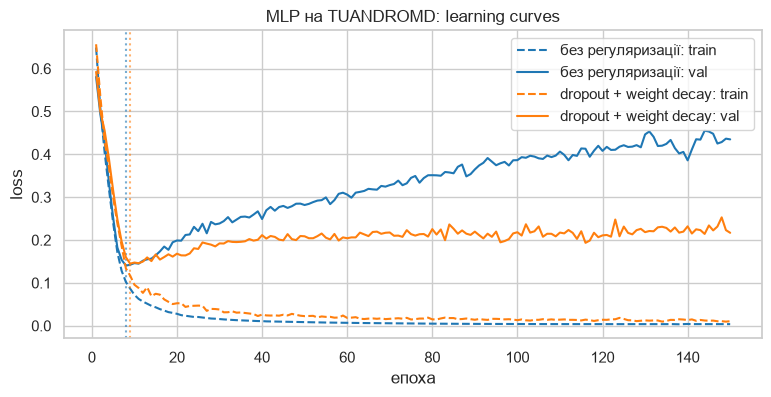

In [8]:
set_seed()
mlp_reg = MLP(X.shape[1], dropout=0.3)
optimizer = torch.optim.Adam(mlp_reg.parameters(), lr=1e-3, weight_decay=1e-3)

hist_reg = fit(mlp_reg, tab_train_loader, tab_val_loader, optimizer, criterion, device_cpu,
               n_epochs=150, val_y=y_val, verbose=False)
print('Найкраща епоха за val loss:', hist_reg['best_epoch'])

plot_curves({'без регуляризації': hist_plain, 'dropout + weight decay': hist_reg}, 'MLP на TUANDROMD: learning curves')

Перенавчання видно дуже чітко. Без регуляризації train loss за кілька десятків епох падає майже до нуля, а val loss досягає мінімуму вже на 8-й епосі (близько 0.15), а потім весь час росте і до 150-ї епохи доходить приблизно до 0.4. Тобто мережа далі вже не вчиться, а запам'ятовує train.

З dropout і weight decay картина та сама, але слабша, val loss після 9-ї епохи росте повільніше і зупиняється десь на 0.2. Отже, регуляризація зменшує перенавчання, але не прибирає його повністю, і головне тут саме рання зупинка. Функція fit повертає ваги з 8-ї і 9-ї епохи відповідно.

In [9]:
for name, m, h in [('MLP без регуляризації', mlp_plain, hist_plain),
                   ('MLP з регуляризацією', mlp_reg, hist_reg)]:
    pred = predict(m, tab_test_loader, device_cpu)
    print(f"=============== {name} (ваги з епохи {h['best_epoch']}) ===============")
    print(classification_report(y_test, pred, target_names=['goodware', 'malware'], digits=3))

=============== MLP без регуляризації (ваги з епохи 8) ===============
              precision    recall  f1-score   support

    goodware      0.970     0.970     0.970       133
     malware      0.879     0.879     0.879        33

    accuracy                          0.952       166
   macro avg      0.924     0.924     0.924       166
weighted avg      0.952     0.952     0.952       166

=============== MLP з регуляризацією (ваги з епохи 9) ===============
              precision    recall  f1-score   support

    goodware      0.963     0.970     0.966       133
     malware      0.875     0.848     0.862        33

    accuracy                          0.946       166
   macro avg      0.919     0.909     0.914       166
weighted avg      0.945     0.946     0.945       166



Обидві мережі дають майже однаковий результат. Без регуляризації знайдено 29 з 33 шкідливих застосунків (F1 = 0.879), з регуляризацією 28 (F1 = 0.862). Різниця в один застосунок, тому це скоріше випадковість, ніж реальна перевага.

Тестова вибірка маленька, тому MLP навчено ще 5 разів з різними seed і результат усереднено. Класичні моделі з найкращими параметрами з лаби 1 навчено на тих самих даних.

In [10]:
# тест маленький (33 malware), тому MLP навчено 5 разів з різними seed
mlp_f1 = []
for seed in range(5):
    set_seed(seed)
    m = MLP(X.shape[1], dropout=0.3)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=1e-3)
    fit(m, tab_train_loader, tab_val_loader, opt, criterion, device_cpu, n_epochs=150, verbose=False)
    mlp_f1.append(f1_score(y_test, predict(m, tab_test_loader, device_cpu)))
print('F1 (malware) MLP за 5 запусків:', np.round(mlp_f1, 3))

# класичні моделі з найкращими параметрами з лаби 1, той самий train/test
classic = {
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=20, random_state=RANDOM_STATE),
    'SVM': SVC(C=10, gamma=0.1),
    'kNN': KNeighborsClassifier(n_neighbors=3),
}
rows = [{'Модель': 'MLP (середнє з 5)', 'test F1 (malware)': np.mean(mlp_f1), 'розкид (std)': np.std(mlp_f1)}]
for name, m in classic.items():
    m.fit(X_train_full, y_train_full)
    rows.append({'Модель': name, 'test F1 (malware)': f1_score(y_test, m.predict(X_test)), 'розкид (std)': 0.0})

pd.DataFrame(rows).set_index('Модель').round(3)

F1 (malware) MLP за 5 запусків: [0.882 0.879 0.879 0.896 0.866]


,test F1 (malware),розкид (std)
Модель,,
MLP (середнє з 5),0.880,0.01
Random Forest,0.875,0.00
SVM,0.892,0.00
kNN,0.875,0.00


У середньому MLP дає F1 = 0.880 з невеликим розкидом, тобто приблизно як Random Forest і kNN (0.875) і трохи гірше за SVM (0.892). Тобто нейромережа тут працює на рівні класичних моделей, але кращою не стала. Для невеликого табличного датасету з бінарними ознаками це очікувано. Класичним моделям не потрібна окрема валідація і рання зупинка, вони швидше навчаються, а Random Forest ще й показує важливість ознак. Тому для цих даних нейромережа особливої переваги не дає.

<h2>[II] Згорткові нейронні мережі</h2>

<p align="center"><i><ins>[II.a] Датасет</ins></i></p>


Для класифікації зображень обрано датасет Fast Food Classification V2 (https://www.kaggle.com/datasets/utkarshsaxenadn/fast-food-classification-dataset) з Kaggle. У ньому фото 10 видів фастфуду, вже розділені на Train, Valid і Test. Окрема папка TFRecords містить ті самі фото у форматі TensorFlow і тут не використовується.

In [11]:
IMG_ROOT = 'Fast Food Classification V2'
IMG_SIZE = 128          # усі фото зменшуємо до 128x128

classes = sorted(d for d in os.listdir(os.path.join(IMG_ROOT, 'Train'))
                 if os.path.isdir(os.path.join(IMG_ROOT, 'Train', d)))
class_to_idx = {c: i for i, c in enumerate(classes)}

def list_split(split):
    files, labels = [], []
    for c in classes:
        for f in sorted(glob.glob(os.path.join(IMG_ROOT, split, c, '*'))):
            if f.lower().endswith(('.jpg', '.jpeg', '.png')):
                files.append(f)
                labels.append(class_to_idx[c])
    return files, np.array(labels)

splits = {s: list_split(s) for s in ['Train', 'Valid', 'Test']}

counts = pd.DataFrame({s: pd.Series(lbl).map(dict(enumerate(classes))).value_counts()
                       for s, (_, lbl) in splits.items()}).loc[classes]
counts.loc['Усього'] = counts.sum()
counts

,Train,Valid,Test
Baked Potato,1500,400,100
Burger,1500,300,200
Crispy Chicken,1500,400,100
Donut,1500,300,200
Fries,1500,400,100
Hot Dog,1500,300,200
Pizza,1500,300,200
Sandwich,1500,300,200
Taco,1500,400,100
Taquito,1500,400,100


Усього 20 тисяч фото. Train ідеально збалансований (по 1500 на клас), а у Valid і Test класів по 100-400 фото, тому крім accuracy далі дивимось ще на F1-macro.

In [12]:
sizes = []
for f in random.sample(splits['Train'][0], 500):
    with Image.open(f) as im:
        sizes.append(im.size)
sizes = pd.DataFrame(sizes, columns=['ширина', 'висота'])
print('Розміри 500 випадкових фото з train:')
print(sizes.describe().loc[['min', '50%', 'max']].astype(int))

Розміри 500 випадкових фото з train:
     ширина  висота
min     100     100
50%     235     201
max     920     920


Фото мають різний розмір, від 100x100 до 920x920, тому всі вони далі приводяться до одного розміру.

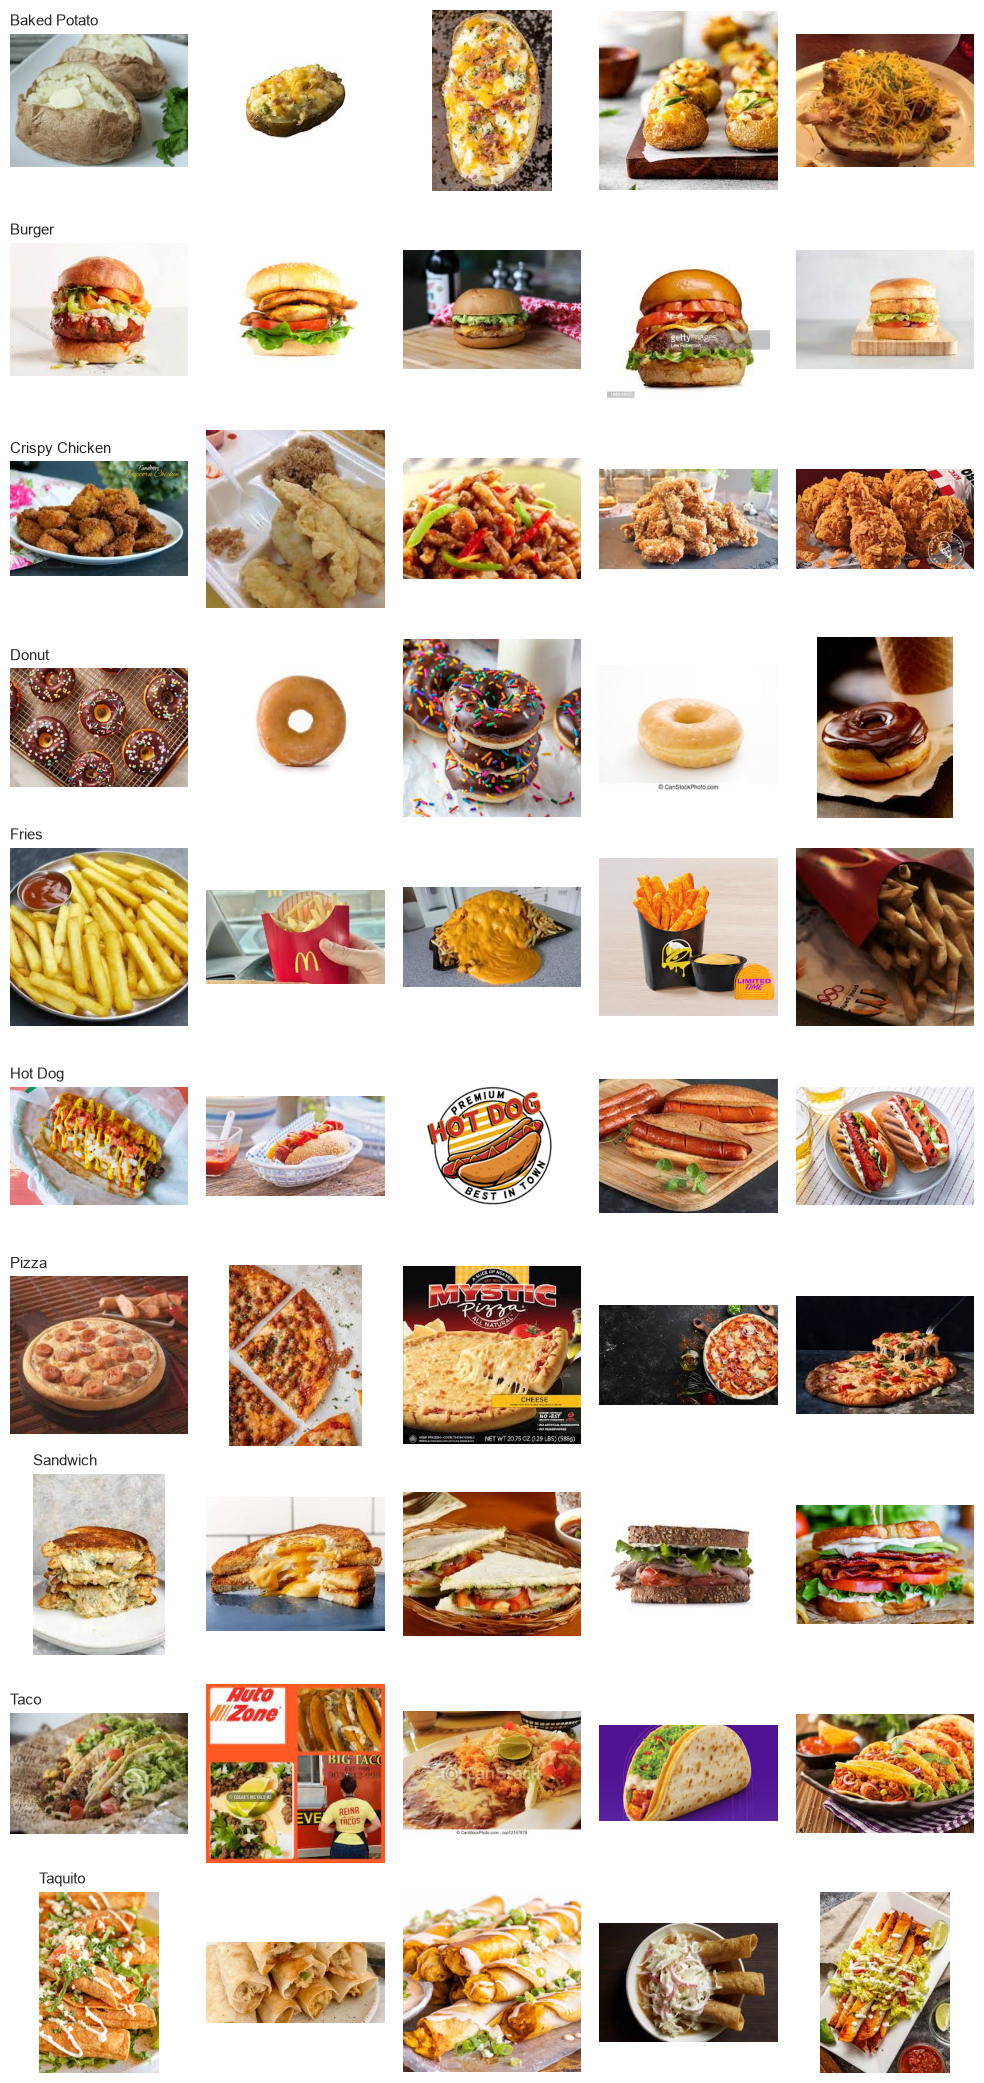

In [13]:
fig, axes = plt.subplots(len(classes), 5, figsize=(10, 2.1 * len(classes)))
for i, c in enumerate(classes):
    files = [f for f, l in zip(*splits['Train']) if l == i]
    for j, f in enumerate(random.sample(files, 5)):
        axes[i, j].imshow(Image.open(f).convert('RGB'))
        axes[i, j].axis('off')
    axes[i, 0].set_title(c, loc='left', fontsize=11)
plt.tight_layout()
plt.show()

Фото зібрані з інтернету, тому вони дуже різні: різний фон, ракурс, кількість їжі в кадрі. Частина взагалі не є звичайними фото їжі, наприклад логотип хот-дога, коробка піци, реклама з тако, а на деяких є водяні знаки фотостоків. Також деякі класи схожі між собою. Тако і такіто зроблені з тієї самої тортильї, а бургер і сендвіч зовні теж досить схожі. МММ НЯМ-НЯМ, смакота!!!

<p align="center"><i><ins>[II.b] Підготовка зображень</ins></i></p>


Усі фото один раз зчитано і зменшено до 128x128, щоб не декодувати JPEG на кожній епосі. Для навчання додано просту аугментацію (віддзеркалення і невеликий зсув), а значення пікселів нормалізовано статистиками ImageNet, бо саме їх очікує pretrained модель.

In [14]:
def load_images(files):
    # читаємо всі фото один раз і зберігаємо як uint8-тензор [N, 3, H, W]
    arr = np.empty((len(files), 3, IMG_SIZE, IMG_SIZE), dtype=np.uint8)
    for i, f in enumerate(files):
        with Image.open(f) as im:
            im = im.convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        arr[i] = np.asarray(im).transpose(2, 0, 1)
    return torch.from_numpy(arr)

t0 = time.perf_counter()
img_data = {s: (load_images(files), torch.tensor(lbl)) for s, (files, lbl) in splits.items()}
print(f'Завантажено за {time.perf_counter() - t0:.0f} c')
for s, (xs, ys) in img_data.items():
    print(s, tuple(xs.shape))

Завантажено за 11 c
Train (15000, 3, 128, 128)
Valid (3500, 3, 128, 128)
Test (1500, 3, 128, 128)


In [15]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device_img)   # статистики ImageNet
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device_img)

def eval_tf(x):
    # uint8 -> float у [0, 1] -> нормалізація
    return (x.float() / 255 - MEAN) / STD

def train_tf(x):
    # проста аугментація: випадкове віддзеркалення і зсув на кілька пікселів
    flip = torch.rand(x.size(0), device=x.device) < 0.5
    x = torch.where(flip.view(-1, 1, 1, 1), x.flip(3), x)
    dx, dy = np.random.randint(-8, 9, size=2)
    x = torch.roll(x, shifts=(int(dy), int(dx)), dims=(2, 3))
    return eval_tf(x)

BATCH = 64

def img_loader(split, idx=None, shuffle=False):
    xs, ys = img_data[split]
    if idx is not None:
        xs, ys = xs[idx], ys[idx]
    return DataLoader(TensorDataset(xs, ys), batch_size=BATCH, shuffle=shuffle)

img_train_loader = img_loader('Train', shuffle=True)
img_val_loader = img_loader('Valid')
img_test_loader = img_loader('Test')
y_img_val = img_data['Valid'][1].numpy()
y_img_test = img_data['Test'][1].numpy()

<p align="center"><i><ins>[II.c] Проста CNN з нуля</ins></i></p>


Мережа має 3 згорткові блоки (згортка, BatchNorm, ReLU, MaxPool) і повнозв'язний класифікатор з dropout.

In [16]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),    # 128 -> 64
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),   # 64 -> 32
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2), # 32 -> 16
            nn.AdaptiveAvgPool2d(4),                                                           # 16 -> 4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(256, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

print(SimpleCNN(len(classes)))
print('Параметрів:', sum(p.numel() for p in SimpleCNN(len(classes)).parameters()))

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=4)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in

In [17]:
EPOCHS_CNN = 20

set_seed()
cnn = SimpleCNN(len(classes)).to(device_img)
img_criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cnn.parameters(), lr=1e-3)

hist_cnn = fit(cnn, img_train_loader, img_val_loader, optimizer, img_criterion, device_img,
               n_epochs=EPOCHS_CNN, train_tf=train_tf, eval_tf=eval_tf, val_y=y_img_val)

[01] train_loss=2.0077 | val_loss=1.8003 | val_acc=0.355 | 17.3 c
[02] train_loss=1.7841 | val_loss=1.6444 | val_acc=0.431 | 15.0 c
[03] train_loss=1.6583 | val_loss=1.5453 | val_acc=0.474 | 14.2 c
[04] train_loss=1.5730 | val_loss=1.4506 | val_acc=0.518 | 14.2 c
[05] train_loss=1.4957 | val_loss=1.4534 | val_acc=0.512 | 14.1 c
[06] train_loss=1.4463 | val_loss=1.4876 | val_acc=0.513 | 14.3 c
[07] train_loss=1.3854 | val_loss=1.3465 | val_acc=0.559 | 14.3 c
[08] train_loss=1.3568 | val_loss=1.3432 | val_acc=0.551 | 14.1 c
[09] train_loss=1.3141 | val_loss=1.3936 | val_acc=0.560 | 14.1 c
[10] train_loss=1.2972 | val_loss=1.4165 | val_acc=0.530 | 14.1 c
[11] train_loss=1.2672 | val_loss=1.2576 | val_acc=0.584 | 14.2 c
[12] train_loss=1.2225 | val_loss=1.1811 | val_acc=0.615 | 14.3 c
[13] train_loss=1.2251 | val_loss=1.1878 | val_acc=0.617 | 14.1 c
[14] train_loss=1.1852 | val_loss=1.2724 | val_acc=0.587 | 14.1 c
[15] train_loss=1.1627 | val_loss=1.2234 | val_acc=0.596 | 14.0 c
[16] train

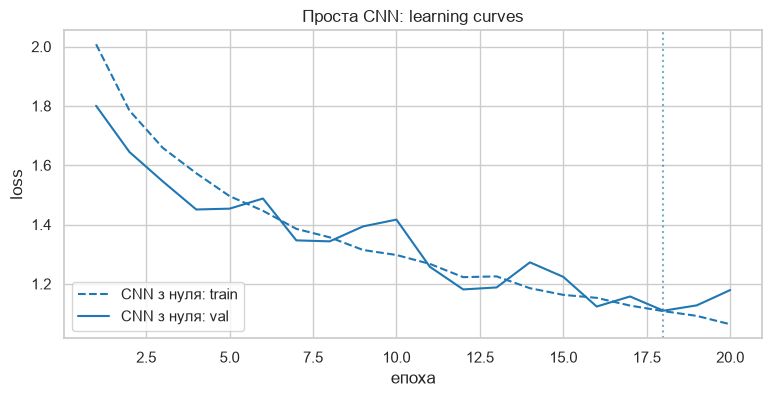

Найкраща епоха: 18 | точність на val: 0.643


In [18]:
plot_curves({'CNN з нуля': hist_cnn}, 'Проста CNN: learning curves')
print('Найкраща епоха:', hist_cnn['best_epoch'], '| точність на val:', round(max(hist_cnn['val_acc']), 3))

CNN вчиться повільно. За 20 епох точність на валідації виросла з 0.36 до приблизно 0.64, найкращий val loss на 18-й епосі. Train loss і val loss весь час йдуть майже поруч, тобто перенавчання немає. Навпаки, модель ще не довчилась (недонавчання), бо обидві криві все ще спадають. Більше епох, скоріш за все, дало б ще трохи, але прогрес під кінець дуже повільний.

<p align="center"><i><ins>[II.d] Pretrained ResNet18</ins></i></p>


Взято ResNet18, попередньо навчену на ImageNet. Її останній шар (1000 класів ImageNet) замінено на новий на 10 класів, і вся мережа донавчається з маленьким learning rate.

In [19]:
def make_resnet(n_classes):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)   # ваги, навчені на ImageNet
    model.fc = nn.Linear(model.fc.in_features, n_classes)              # новий класифікатор під наші класи
    return model

resnet = make_resnet(len(classes))
print('Новий класифікатор:', resnet.fc)
print('Параметрів:', sum(p.numel() for p in resnet.parameters()))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/administrator/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%


Новий класифікатор: Linear(in_features=512, out_features=10, bias=True)
Параметрів: 11181642


In [20]:
EPOCHS_RESNET = 8

set_seed()
resnet = make_resnet(len(classes)).to(device_img)
optimizer = torch.optim.Adam(resnet.parameters(), lr=1e-4)   # маленький lr, щоб не зламати готові ваги

hist_resnet = fit(resnet, img_train_loader, img_val_loader, optimizer, img_criterion, device_img,
                  n_epochs=EPOCHS_RESNET, train_tf=train_tf, eval_tf=eval_tf, val_y=y_img_val)

[01] train_loss=0.8228 | val_loss=0.6852 | val_acc=0.787 | 24.1 c
[02] train_loss=0.4031 | val_loss=0.6371 | val_acc=0.807 | 19.8 c
[03] train_loss=0.2821 | val_loss=0.6408 | val_acc=0.818 | 19.7 c
[04] train_loss=0.1835 | val_loss=0.6256 | val_acc=0.832 | 19.6 c
[05] train_loss=0.1425 | val_loss=0.6305 | val_acc=0.826 | 19.7 c
[06] train_loss=0.1056 | val_loss=0.6742 | val_acc=0.827 | 19.7 c
[07] train_loss=0.0839 | val_loss=0.7137 | val_acc=0.828 | 19.7 c
[08] train_loss=0.0692 | val_loss=0.7309 | val_acc=0.830 | 19.7 c


Вже після першої епохи ResNet18 має точність 0.79 на валідації, тобто більше, ніж CNN після всіх 20 епох. Найкращий val loss на 4-й епосі, а далі він починає рости, хоча train loss падає до 0.07. Отже, після 4-ї епохи ResNet18 уже перенавчається. Це логічно, бо параметрів у неї 11 мільйонів проти 0.6 мільйона в простій CNN. Точність на валідації при цьому тримається близько 0.83, а ваги взято з 4-ї епохи.

<p align="center"><i><ins>[II.e] Порівняння моделей</ins></i></p>

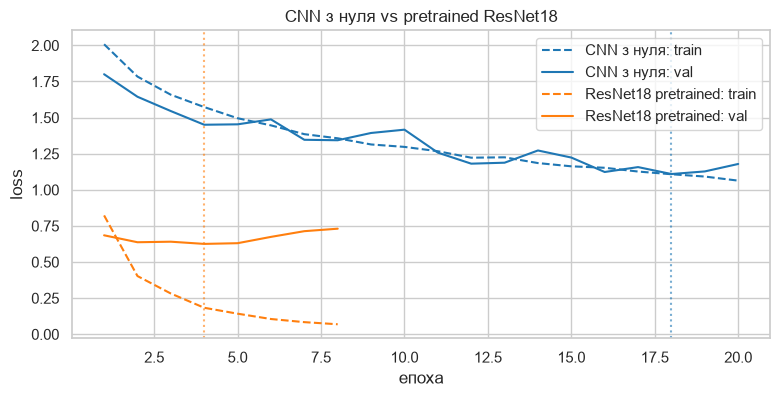

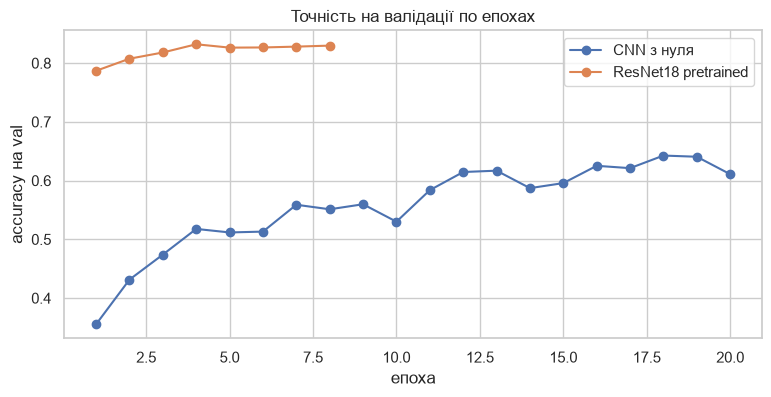

In [21]:
plot_curves({'CNN з нуля': hist_cnn, 'ResNet18 pretrained': hist_resnet},
            'CNN з нуля vs pretrained ResNet18')

plt.figure(figsize=(9, 4))
plt.plot(range(1, len(hist_cnn['val_acc']) + 1), hist_cnn['val_acc'], marker='o', label='CNN з нуля')
plt.plot(range(1, len(hist_resnet['val_acc']) + 1), hist_resnet['val_acc'], marker='o', label='ResNet18 pretrained')
plt.xlabel('епоха'); plt.ylabel('accuracy на val'); plt.title('Точність на валідації по епохах')
plt.legend()
plt.show()

На графіках добре видно різницю. Val loss у ResNet18 з першої ж епохи значно нижчий (0.69 проти 1.80), а точність 0.79 проти 0.36. ResNet18 виходить на свій рівень за 1-4 епохи, а CNN повільно повзе вгору всі 20. Також у моделей різні проблеми типу CNN недонавчена (train і val майже однакові), а ResNet18 перенавчається (між train і val з'являється розрив).

In [22]:
img_results = {}
for name, m, h in [('CNN з нуля', cnn, hist_cnn), ('ResNet18 pretrained', resnet, hist_resnet)]:
    pred = predict(m, img_test_loader, device_img, eval_tf)
    img_results[name] = pred
    print(f'=============== {name} ===============')
    print(classification_report(y_img_test, pred, target_names=classes, digits=3))

pd.DataFrame({
    name: {'test accuracy': accuracy_score(y_img_test, p),
           'test F1-macro': f1_score(y_img_test, p, average='macro'),
           'найкраща епоха': h['best_epoch'],
           'епох для val acc >= 0.7': next((i + 1 for i, a in enumerate(h['val_acc']) if a >= 0.7), None),
           'сек на епоху': np.mean(h['time'])}
    for (name, p), h in zip(img_results.items(), [hist_cnn, hist_resnet])
}).T.round(3)

=============== CNN з нуля ===============
                precision    recall  f1-score   support

  Baked Potato      0.563     0.850     0.677       100
        Burger      0.680     0.660     0.670       200
Crispy Chicken      0.761     0.830     0.794       100
         Donut      0.883     0.790     0.834       200
         Fries      0.688     0.640     0.663       100
       Hot Dog      0.743     0.390     0.511       200
         Pizza      0.705     0.790     0.745       200
      Sandwich      0.582     0.570     0.576       200
          Taco      0.374     0.800     0.510       100
       Taquito      0.143     0.050     0.074       100

      accuracy                          0.638      1500
     macro avg      0.612     0.637     0.605      1500
  weighted avg      0.648     0.638     0.626      1500

=============== ResNet18 pretrained ===============
                precision    recall  f1-score   support

  Baked Potato      0.869     0.930     0.899       100
     

,test accuracy,test F1-macro,найкраща епоха,епох для val acc >= 0.7,сек на епоху
CNN з нуля,0.638,0.605,18.0,NaN,14.333
ResNet18 pretrained,0.841,0.825,4.0,1.0,20.245


На тесті ResNet18 краща на 20% (accuracy 0.841 проти 0.638), F1-macro 0.825 проти 0.605. Точності 0.7 на валідації ResNet18 досягла вже на першій епосі, а CNN не досягла взагалі. Одна епоха ResNet18 трохи довша (20 с проти 14 с), але до найкращого результату їй треба 4 епохи (приблизно півтори хв), а CNN 18 епох (понад 4 хв).

Найгірше обом моделям дається такіто. У CNN F1 для цього класу лише 0.074, тобто вона його майже не розпізнає, у ResNet18 0.571.

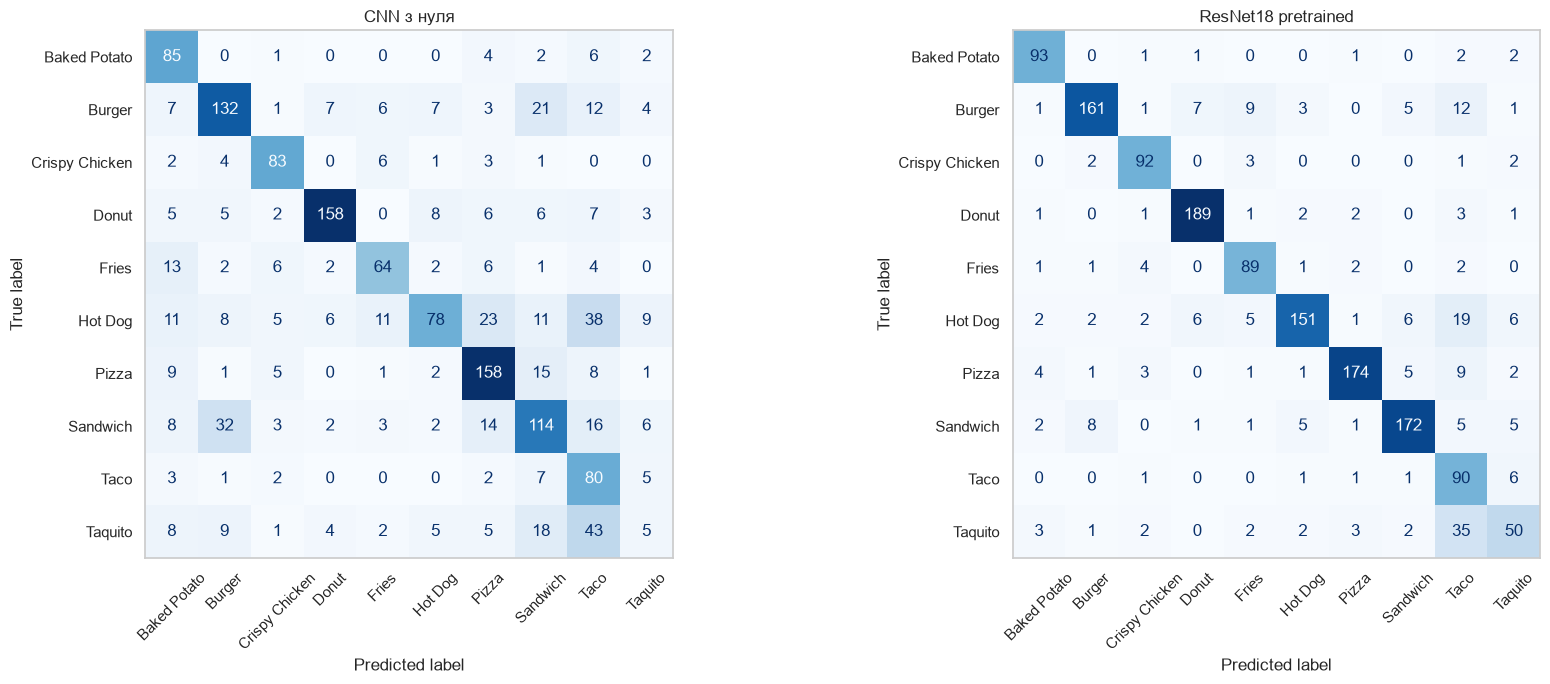

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, (name, pred) in zip(axes, img_results.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_img_test, pred), display_labels=classes).plot(
        ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
    ax.set_title(name); ax.grid(False)
plt.tight_layout()
plt.show()

З матриць видно, що найчастіше моделі плутають схожі страви. Такіто вони відносять до тако (CNN 43 з 100, ResNet18 35), хот-дог теж часто стає тако, а CNN ще плутає бургер і сендвіч. ResNet18 майже прибрала плутанину між бургером і сендвічем, а от тако і такіто розрізняє погано навіть вона, бо зовні вони дуже схожі, і в датасеті є шумні фото.

Окремо перевірено, як обидві моделі працюють, якщо тренувальних фото менше. Для цього їх навчено на 10%, 25% і 50% train з тією самою кількістю епох.

10% train (1500 фото) | CNN з нуля: test accuracy = 0.436
10% train (1500 фото) | ResNet18 pretrained: test accuracy = 0.739
25% train (3750 фото) | CNN з нуля: test accuracy = 0.547
25% train (3750 фото) | ResNet18 pretrained: test accuracy = 0.759
50% train (7500 фото) | CNN з нуля: test accuracy = 0.557
50% train (7500 фото) | ResNet18 pretrained: test accuracy = 0.810


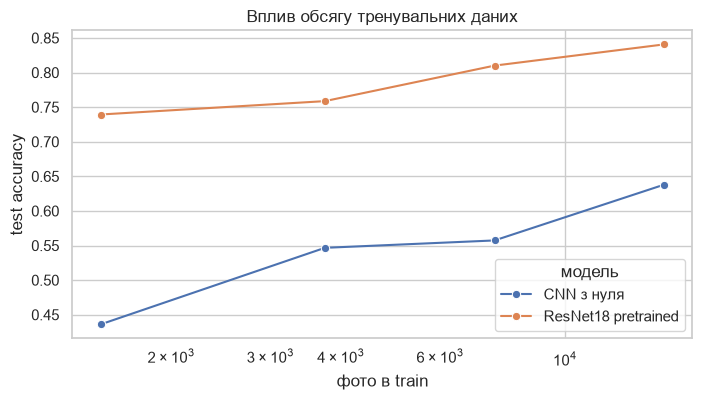

модель,CNN з нуля,ResNet18 pretrained
фото в train,,
1500,0.436,0.739
3750,0.547,0.759
7500,0.557,0.810
15000,0.638,0.841


In [24]:
# частина train-фото (стратифіковано), кількість епох та сама
fractions = [0.1, 0.25, 0.5]
y_img_train = img_data['Train'][1].numpy()
size_rows = []
for frac in fractions:
    idx, _ = train_test_split(np.arange(len(y_img_train)), train_size=frac,
                              stratify=y_img_train, random_state=RANDOM_STATE)
    loader = img_loader('Train', idx=torch.tensor(idx), shuffle=True)
    for name, make, epochs, lr in [('CNN з нуля', lambda: SimpleCNN(len(classes)), EPOCHS_CNN, 1e-3),
                                   ('ResNet18 pretrained', lambda: make_resnet(len(classes)), EPOCHS_RESNET, 1e-4)]:
        set_seed()
        m = make().to(device_img)
        opt = torch.optim.Adam(m.parameters(), lr=lr)
        fit(m, loader, img_val_loader, opt, img_criterion, device_img, n_epochs=epochs,
            train_tf=train_tf, eval_tf=eval_tf, verbose=False)
        acc = accuracy_score(y_img_test, predict(m, img_test_loader, device_img, eval_tf))
        size_rows.append({'частка train': frac, 'фото в train': len(idx), 'модель': name, 'test accuracy': acc})
        print(f'{frac:.0%} train ({len(idx)} фото) | {name}: test accuracy = {acc:.3f}')

for name in img_results:   # повний train вже навчений вище
    size_rows.append({'частка train': 1.0, 'фото в train': len(y_img_train), 'модель': name,
                      'test accuracy': accuracy_score(y_img_test, img_results[name])})

size_df = pd.DataFrame(size_rows)
plt.figure(figsize=(8, 4))
sns.lineplot(size_df, x='фото в train', y='test accuracy', hue='модель', marker='o')
plt.xscale('log'); plt.title('Вплив обсягу тренувальних даних')
plt.show()

size_df.pivot(index='фото в train', columns='модель', values='test accuracy').round(3)

ResNet18, навчена лише на 1500 фото (10% train), дає 0.739. Це більше, ніж CNN на всіх 15000 фото (0.638). Якщо даних мало, різниця між моделями найбільша (0.30 при 10% train), а з ростом кількості фото вона зменшується до 0.20. CNN з нуля потрібно самій навчитись бачити краї, текстури і форми, а ResNet18 це вже вміє з ImageNet, тому їй вистачає набагато менше прикладів. Варто враховувати, що кількість епох була однакова, тож на малій вибірці CNN робила і менше кроків навчання.

Отже, pretrained модель тут краща за всіма пунктами: точністю, швидкістю збіжності і роботою на малих даних.

<h2>[III] Нейронні мережі для класифікації текстів</h2>

<p align="center"><i><ins>[III.a] Дані і токенізація</ins></i></p>


Використано той самий датасет описів вразливостей CVE з лаби 2 (3 класи: XSS, SQLi, CSRF) і той самий test. З train відкладено 20% на валідацію.

In [25]:
texts = pd.read_csv('cve_2024_vuln_types.csv')
txt_classes = ['XSS', 'SQLi', 'CSRF']
texts['y'] = texts['label'].map({c: i for i, c in enumerate(txt_classes)})

# той самий test, що в лабі 2, а з train відкладаємо 20% на валідацію
tr_df, te_df = train_test_split(texts, test_size=0.25, stratify=texts['label'], random_state=RANDOM_STATE)
tr_df, va_df = train_test_split(tr_df, test_size=0.2, stratify=tr_df['label'], random_state=RANDOM_STATE)
print('Train:', len(tr_df), '| Val:', len(va_df), '| Test:', len(te_df))

Train: 1800 | Val: 450 | Test: 750


Текст переведено в нижній регістр, прибрано посилання і шляхи до файлів, а потім розбито на слова. Стоп-слова тут не видалялись, бо LSTM читає текст послідовно і службові слова теж несуть частину змісту.

In [26]:
def tokenize(text):
    text = text.lower()
    text = re.sub(r'https?://\S+', ' ', text)   # посилання
    text = re.sub(r'\S*/\S*', ' ', text)        # шляхи до файлів
    return re.findall(r'[a-z]+', text)          # тільки слова з латинських літер

for df_ in (tr_df, va_df, te_df):
    df_['tokens'] = df_['description'].map(tokenize)

print('Приклад:', tr_df['tokens'].iloc[0][:25])
lens = tr_df['tokens'].map(len)
print('\nДовжина описів у токенах:', lens.describe()[['mean', '50%', 'max']].round(0).to_dict(),
      '| 95-й перцентиль:', int(lens.quantile(0.95)))

Приклад: ['improper', 'neutralization', 'of', 'input', 'during', 'web', 'page', 'generation', 'xss', 'or', 'cross', 'site', 'scripting', 'vulnerability', 'in', 'ymc', 'filter', 'grids', 'allows', 'stored', 'xss', 'this', 'issue', 'affects', 'filter']

Довжина описів у токенах: {'mean': 50.0, '50%': 48.0, 'max': 331.0} | 95-й перцентиль: 84


У середньому опис має 50 слів, а 95% описів коротші за 84 слова. Тому довжину послідовності взято 100. Так майже всі тексти поміщаються повністю, і обрізаються лише поодинокі довгі описи.

<p align="center"><i><ins>[III.b] Словник, індекси і padding</ins></i></p>


Словник побудовано тільки з train, рідкісні слова (менше 2 разів) замінюються на [UNK]. Кожен опис перетворено в послідовність індексів і приведено до довжини 100 (довші обрізаються, коротші доповнюються [PAD]).

In [27]:
counter = Counter(t for toks in tr_df['tokens'] for t in toks)   # словник тільки з train
MIN_FREQ = 2
itos = ['[PAD]', '[UNK]'] + [w for w, c in counter.most_common() if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}
PAD_IDX, UNK_IDX = 0, 1
print('Унікальних слів у train:', len(counter), '| розмір словника (min_freq=2):', len(itos))

MAX_LEN = 100

def encode(tokens):
    ids = [stoi.get(t, UNK_IDX) for t in tokens][:MAX_LEN]           # truncation
    return ids + [PAD_IDX] * (MAX_LEN - len(ids)), max(len(ids), 1)  # padding

def make_text_loader(df_, shuffle=False):
    # у кожному прикладі зберігаємо і індекси слів, і справжню довжину опису (вона потрібна для LSTM)
    enc = [encode(t) for t in df_['tokens']]
    ids = torch.tensor([e[0] for e in enc])
    lengths = torch.tensor([e[1] for e in enc])
    ds = TensorDataset(torch.stack([ids, lengths.unsqueeze(1).expand(-1, MAX_LEN)], dim=1),
                       torch.tensor(df_['y'].values))
    return DataLoader(ds, batch_size=64, shuffle=shuffle)

txt_train_loader = make_text_loader(tr_df, shuffle=True)
txt_val_loader = make_text_loader(va_df)
txt_test_loader = make_text_loader(te_df)

print('\nПриклад закодованого опису:', encode(tr_df['tokens'].iloc[0])[0][:20], '...')

Унікальних слів у train: 4446 | розмір словника (min_freq=2): 2487

Приклад закодованого опису: [69, 70, 9, 50, 97, 37, 40, 98, 53, 81, 12, 10, 32, 8, 4, 1, 268, 1740, 36, 48] ...


З 4446 різних слів у train лише трохи більше половини трапляються хоча б двічі. Решта здебільшого є назвами продуктів і компаній, які зустрічаються один раз. У прикладі видно, що слово ymc (назва плагіна) отримало індекс 1, тобто [UNK], бо в train воно трапилось лише один раз.

<p align="center"><i><ins>[III.c] BiLSTM з випадковими embeddings</ins></i></p>


Модель складається з Embedding-шару (100 вимірів), двонапрямленого LSTM (64 нейрони в кожен бік) і лінійного класифікатора. Щоб LSTM не читав PAD-токени, використано pack_padded_sequence.

In [28]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim, n_classes, emb_weights=None, freeze_emb=False):
        super().__init__()
        if emb_weights is None:
            self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_IDX)   # випадкові ваги
        else:
            self.embedding = nn.Embedding.from_pretrained(emb_weights, freeze=freeze_emb, padding_idx=PAD_IDX)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim * 2, n_classes)

    def forward(self, x):
        ids, lengths = x[:, 0, :], x[:, 1, 0]
        emb = self.embedding(ids)
        # pack_padded_sequence: LSTM не читає PAD-токени в кінці
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        h = torch.cat([h[-2], h[-1]], dim=1)     # останні стани прямого і зворотного проходу
        return self.fc(self.dropout(h))

EMB_DIM, HIDDEN = 100, 64
print(LSTMClassifier(len(itos), EMB_DIM, HIDDEN, len(txt_classes)))

LSTMClassifier(
  (embedding): Embedding(2487, 100, padding_idx=0)
  (lstm): LSTM(100, 64, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=3, bias=True)
)


In [29]:
EPOCHS_TXT = 15
txt_criterion = nn.CrossEntropyLoss()
y_txt_val = va_df['y'].values
y_txt_test = te_df['y'].values

set_seed()
lstm_rand = LSTMClassifier(len(itos), EMB_DIM, HIDDEN, len(txt_classes))
optimizer = torch.optim.Adam(lstm_rand.parameters(), lr=1e-3)
hist_rand = fit(lstm_rand, txt_train_loader, txt_val_loader, optimizer, txt_criterion, device_cpu, n_epochs=EPOCHS_TXT, val_y=y_txt_val)

[01] train_loss=0.8281 | val_loss=0.6197 | val_acc=0.796 | 2.8 c
[02] train_loss=0.5059 | val_loss=0.4444 | val_acc=0.842 | 2.8 c
[03] train_loss=0.2665 | val_loss=0.1196 | val_acc=0.967 | 2.9 c
[04] train_loss=0.0838 | val_loss=0.0959 | val_acc=0.976 | 3.1 c
[05] train_loss=0.0751 | val_loss=0.0736 | val_acc=0.982 | 2.8 c
[06] train_loss=0.0376 | val_loss=0.0699 | val_acc=0.984 | 2.9 c
[07] train_loss=0.0249 | val_loss=0.0607 | val_acc=0.982 | 2.9 c
[08] train_loss=0.0224 | val_loss=0.0963 | val_acc=0.969 | 2.9 c
[09] train_loss=0.0285 | val_loss=0.0603 | val_acc=0.982 | 3.0 c
[10] train_loss=0.0142 | val_loss=0.0616 | val_acc=0.984 | 2.9 c
[11] train_loss=0.0125 | val_loss=0.0683 | val_acc=0.987 | 3.0 c
[12] train_loss=0.0074 | val_loss=0.0665 | val_acc=0.989 | 2.9 c
[13] train_loss=0.0047 | val_loss=0.0742 | val_acc=0.984 | 2.8 c
[14] train_loss=0.0068 | val_loss=0.0742 | val_acc=0.987 | 3.0 c
[15] train_loss=0.0026 | val_loss=0.0700 | val_acc=0.989 | 2.8 c


Модель навчилась швидко, вже на 3-й епосі точність на валідації 0.967. Найкращий val loss на 9-й епосі. Після цього train loss падає майже до нуля, а val loss тримається приблизно на тому ж рівні, тобто є невелике перенавчання, але якість від нього майже не страждає.

<p align="center"><i><ins>[III.d] BiLSTM з GloVe</ins></i></p>


Завантажено готові вектори GloVe (100 вимірів, навчені на Вікіпедії і новинах) і ними ініціалізовано Embedding-шар. Слова, яких немає в GloVe, отримують випадкові вектори. Embeddings далі донавчаються разом з моделлю.

In [30]:
GLOVE_URL = ('https://github.com/RaRe-Technologies/gensim-data/releases/download/'
             'glove-wiki-gigaword-100/glove-wiki-gigaword-100.gz')
GLOVE_FILE = 'glove-wiki-gigaword-100.gz'
if not os.path.exists(GLOVE_FILE):
    print('Завантажую GloVe (~130 МБ)...')
    urllib.request.urlretrieve(GLOVE_URL, GLOVE_FILE)

# беремо вектори тільки для слів з нашого словника
emb_matrix = np.random.normal(scale=0.1, size=(len(itos), EMB_DIM)).astype(np.float32)
emb_matrix[PAD_IDX] = 0.0
found = set()
with gzip.open(GLOVE_FILE, 'rt', encoding='utf-8') as f:
    next(f)                                   # перший рядок: "400000 100"
    for line in f:
        word, rest = line.split(' ', 1)
        if word in stoi:
            emb_matrix[stoi[word]] = np.asarray(rest.split(), dtype=np.float32)
            found.add(word)

print(f'Покриття словника GloVe: {len(found)} / {len(itos) - 2} слів ({len(found) / (len(itos) - 2):.1%})')
missing = [w for w, _ in counter.most_common() if w in stoi and w not in found][:15]
print('Часті слова, яких немає в GloVe:', missing)

Завантажую GloVe (~130 МБ)...
Покриття словника GloVe: 2058 / 2485 слів (82.8%)
Часті слова, яких немає в GloVe: ['csrf', 'elementor', 'sourcecodester', 'woocommerce', 'shortcode', 'campcodes', 'itsourcecode', 'shortcodes', 'kashipara', 'phpgurukul', 'tinymce', 'dedecms', 'themify', 'chatbot', 'codezips']


GloVe покриває 83% нашого словника. Немає здебільшого назв продуктів і компаній (elementor, woocommerce, sourcecodester), специфічних веб-термінів (shortcode) і, що цікаво, слова csrf. А от xss, sql, injection і scripting у GloVe є.

In [31]:
set_seed()
lstm_glove = LSTMClassifier(len(itos), EMB_DIM, HIDDEN, len(txt_classes),
                            emb_weights=torch.tensor(emb_matrix), freeze_emb=False)
optimizer = torch.optim.Adam(lstm_glove.parameters(), lr=1e-3)
hist_glove = fit(lstm_glove, txt_train_loader, txt_val_loader, optimizer, txt_criterion, device_cpu,
                 n_epochs=EPOCHS_TXT, val_y=y_txt_val)

[01] train_loss=0.8690 | val_loss=0.5960 | val_acc=0.829 | 2.9 c
[02] train_loss=0.3424 | val_loss=0.1906 | val_acc=0.936 | 2.8 c
[03] train_loss=0.2043 | val_loss=0.1096 | val_acc=0.971 | 2.9 c
[04] train_loss=0.0890 | val_loss=0.0801 | val_acc=0.984 | 2.9 c
[05] train_loss=0.0535 | val_loss=0.0868 | val_acc=0.976 | 3.5 c
[06] train_loss=0.1152 | val_loss=0.4499 | val_acc=0.822 | 3.0 c
[07] train_loss=0.2334 | val_loss=0.1980 | val_acc=0.929 | 2.9 c
[08] train_loss=0.1628 | val_loss=0.1891 | val_acc=0.904 | 2.9 c
[09] train_loss=0.2506 | val_loss=0.1722 | val_acc=0.936 | 3.1 c
[10] train_loss=0.1424 | val_loss=0.1361 | val_acc=0.951 | 3.0 c
[11] train_loss=0.0851 | val_loss=0.0887 | val_acc=0.971 | 3.1 c
[12] train_loss=0.0478 | val_loss=0.0735 | val_acc=0.978 | 3.0 c
[13] train_loss=0.0463 | val_loss=0.0649 | val_acc=0.978 | 2.8 c
[14] train_loss=0.0474 | val_loss=0.0706 | val_acc=0.971 | 2.8 c
[15] train_loss=0.0269 | val_loss=0.0504 | val_acc=0.987 | 3.0 c


На початку модель з GloVe вчиться швидше. На 2-й епосі точність 0.936 проти 0.842 у моделі з випадковими ембедінгами. Але на 6-й епосі val loss різко підскочив до 0.45, і кілька епох навчання було нестабільним. Скоріш за все, оптимізатор зробив завеликий крок і зіпсував частину готових векторів. Потім модель відновилась, і до 15-ї епохи вийшла на найменший val loss з обох моделей (0.050).

<p align="center"><i><ins>[III.e] Порівняння двох підходів</ins></i></p>

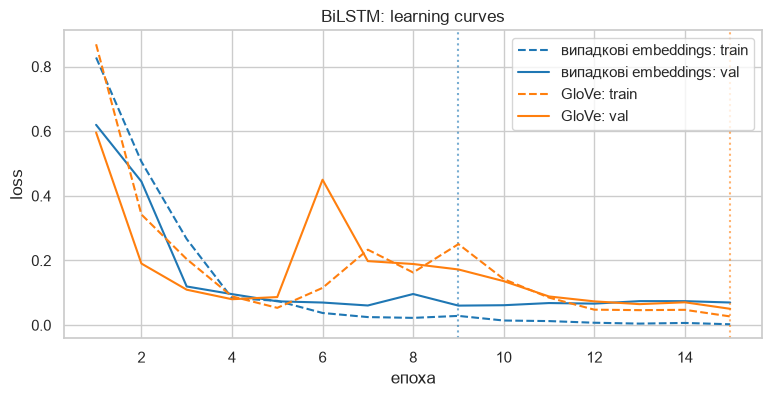

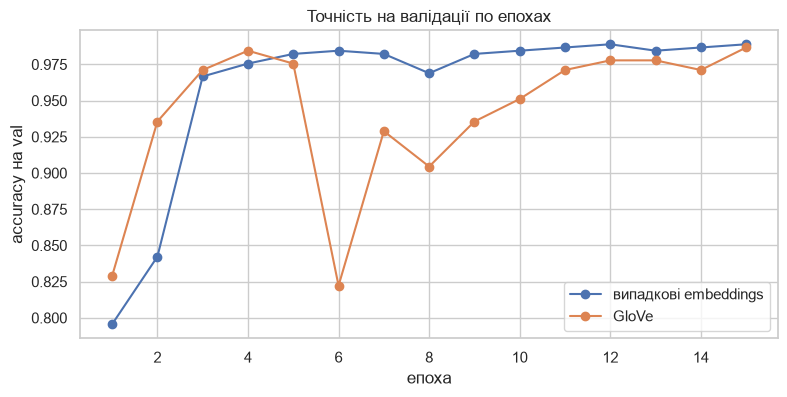

In [32]:
plot_curves({'випадкові embeddings': hist_rand, 'GloVe': hist_glove}, 'BiLSTM: learning curves')

plt.figure(figsize=(9, 4))
for name, h in [('випадкові embeddings', hist_rand), ('GloVe', hist_glove)]:
    plt.plot(range(1, len(h['val_acc']) + 1), h['val_acc'], marker='o', label=name)
plt.xlabel('епоха'); plt.ylabel('accuracy на val'); plt.title('Точність на валідації по епохах')
plt.legend()
plt.show()

На графіках видно, що GloVe дає швидший старт у перші 2-3 епохи, але потім навчання менш стабільне. Модель з випадковими ембедінгами навпаки рівно сходиться без стрибків. Після 11-ї епохи обидві моделі виходять приблизно на однаковий рівень.

=============== випадкові embeddings ===============
              precision    recall  f1-score   support

         XSS      0.976     0.980     0.978       250
        SQLi      0.976     0.996     0.986       250
        CSRF      0.992     0.968     0.980       250

    accuracy                          0.981       750
   macro avg      0.981     0.981     0.981       750
weighted avg      0.981     0.981     0.981       750

=============== GloVe ===============
              precision    recall  f1-score   support

         XSS      0.972     0.988     0.980       250
        SQLi      0.988     0.996     0.992       250
        CSRF      0.992     0.968     0.980       250

    accuracy                          0.984       750
   macro avg      0.984     0.984     0.984       750
weighted avg      0.984     0.984     0.984       750



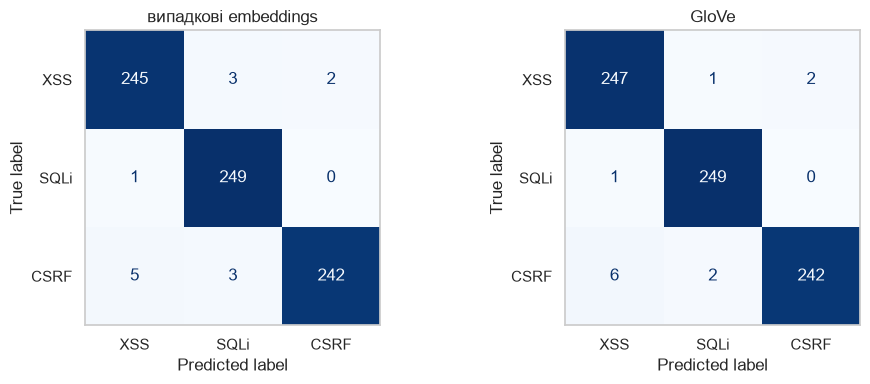

,test F1-macro,найкраща епоха,епох для val acc >= 0.95,сек на епоху
випадкові embeddings,0.981,9.0,3.0,2.900
GloVe,0.984,15.0,3.0,2.969


In [33]:
txt_results = {}
for name, m in [('випадкові embeddings', lstm_rand), ('GloVe', lstm_glove)]:
    pred = predict(m, txt_test_loader, device_cpu)
    txt_results[name] = pred
    print(f'=============== {name} ===============')
    print(classification_report(y_txt_test, pred, target_names=txt_classes, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, txt_results.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_txt_test, pred), display_labels=txt_classes).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name); ax.grid(False)
plt.tight_layout()
plt.show()

pd.DataFrame({
    name: {'test F1-macro': f1_score(y_txt_test, txt_results[name], average='macro'),
           'найкраща епоха': h['best_epoch'],
           'епох для val acc >= 0.95': next((i + 1 for i, a in enumerate(h['val_acc']) if a >= 0.95), None),
           'сек на епоху': np.mean(h['time'])}
    for name, h in [('випадкові embeddings', hist_rand), ('GloVe', hist_glove)]
}).T.round(3)

На тесті різниця мінімальна. F1-macro 0.984 з GloVe проти 0.981 з випадковими embeddings, це лише 2 описи з 750. Найчастіша помилка в обох моделей та сама, що й у лабі 2 - CSRF плутається з XSS. Час епохи однаковий, бо архітектура однакова.

Для порівняння, у лабі 2 звичайна логістична регресія на TF-IDF дала 0.992, тобто навіть трохи більше, і навчалась набагато швидше. Ці описи короткі і шаблонні, а клас часто визначається ключовими словами, тому складна послідовна модель тут не потрібна.

На повних даних задача досить проста, тому окремо перевірено, чи допомагає GloVe, коли тренувальних текстів мало (10% train).

In [34]:
# той самий експеримент на 10% train (~180 описів), 5 запусків з різними seed
small_df, _ = train_test_split(tr_df, train_size=0.1, stratify=tr_df['label'], random_state=RANDOM_STATE)
small_loader = make_text_loader(small_df, shuffle=True)
print('Описів у малому train:', len(small_df))

small_rows = []
for seed in range(5):
    for name, weights in [('випадкові embeddings', None), ('GloVe', torch.tensor(emb_matrix))]:
        set_seed(seed)
        m = LSTMClassifier(len(itos), EMB_DIM, HIDDEN, len(txt_classes), emb_weights=weights)
        opt = torch.optim.Adam(m.parameters(), lr=1e-3)
        fit(m, small_loader, txt_val_loader, opt, txt_criterion, device_cpu, n_epochs=EPOCHS_TXT, verbose=False)
        small_rows.append({'модель': name, 'seed': seed,
                           'test F1-macro': f1_score(y_txt_test, predict(m, txt_test_loader, device_cpu), average='macro')})

pd.DataFrame(small_rows).groupby('модель')['test F1-macro'].agg(['mean', 'std', 'min', 'max']).round(3)

Описів у малому train: 180


,mean,std,min,max
модель,,,,
GloVe,0.892,0.010,0.881,0.904
випадкові embeddings,0.837,0.014,0.814,0.852


На 180 описах різниця вже помітна. З GloVe F1-macro у середньому 0.892, а з випадковими embeddings 0.837, причому найгірший запуск з GloVe (0.881) кращий за найкращий без нього (0.852). Коли даних мало, модель не встигає сама навчитись, які слова схожі за змістом, а GloVe дає їй це готовим. Тобто pretrained embeddings найбільше допомагають саме на малих даних, а на великих їх ефект майже зникає.

<h2>[IV] Загальні висновки</h2>

В ході виконання лабораторної роботи було побудовано і навчено нейронні мережі в PyTorch для табличних даних, зображень і текстів. На невеликому табличному датасеті повнозв'язна мережа швидко перенавчалась і без ранньої зупинки не обійшлась, а за якістю лише зрівнялась з класичними моделями з лаби 1. Для зображень попередньо навчена ResNet18 виявилась значно кращою за CNN з нуля, вона швидше навчалась і давала хороший результат навіть на невеликій частині даних. Для текстів готові вектори GloVe прискорили початок навчання і помітно допомогли при малій кількості даних, а на повному датасеті обидва підходи дали майже однаковий результат. Отже, нейромережі найбільше виграють там, де можна використати попередньо навчені моделі, а на простих і невеликих даних класичні методи працюють не гірше.